In [32]:
%reload_ext autoreload
%autoreload 2

In [33]:
from housepriceprediction.data_description import DataDescription
from housepriceprediction.config import TXT_FILE, DATA_RAW
import pandas as pd

df = pd.read_csv(DATA_RAW / "train.csv", keep_default_na=False, na_values=["NA"])
pd.set_option("display.max_columns", None)
# print(df["GarageType"].isna().sum())
# print(df.select_dtypes("float64").isna().sum())
# print(df.shape)
# print(len(df))
# print(df.head())
# print(df.dtypes.value_counts())
desc = DataDescription(TXT_FILE)
features_with_na = desc.columns_where_na_means_absent
print("Number of unique features with NA:", len(features_with_na))
for index, feature in enumerate(features_with_na):
    print(f"Index {index}: {feature}")


print()

real_cols_with_na = set(df.columns[df.isna().any()])
cols_with_na = set(features_with_na)
replace_with_none = real_cols_with_na & cols_with_na
accidentals = real_cols_with_na - cols_with_na
no_na_in_training = cols_with_na - real_cols_with_na

print("--- 1. To replace with 'None' ---")
print(replace_with_none)
print("\n--- 2. Accidentals ---")
print(df[sorted(accidentals)].isna().sum())
print("\n--- 3. No NA in training ---")
print(no_na_in_training)

print()

# ==========================================
# Task 1: Check if MasVnrType and MasVnrArea have missing values in the same rows
# Build the missingness mask for each column and compare them element-wise.
# Then check if all comparisons are True. Expected result: True.
# ==========================================
result_1 = (df["MasVnrType"].isna() == df["MasVnrArea"].isna()).all()
print("\nTask 1 - MasVnrType & MasVnrArea mask match:", result_1)


# ==========================================
# Task 2: Same idea for GarageType and GarageYrBlt, but with different columns.
# Expected result: True.
# ==========================================
result_2 = (df["GarageType"].isna() == df["GarageYrBlt"].isna()).all()
print("\nTask 2 - GarageType & GarageYrBlt mask match:", result_2)


# ==========================================
# Task 3: How frequent is 'SBrkr' in the 'Electrical' column?
# value_counts() has a parameter that returns proportions instead of absolute counts.
# Expected result: approximately 0.914.
# ==========================================
sbrkr_freq = df["Electrical"].value_counts(normalize=True)["SBrkr"]
print("\nTask 3 - Electrical 'SBrkr' frequency:", sbrkr_freq)


# ==========================================
# Task 4: For how many houses with a garage is the garage year built identical to the house year built?
# This supports the 79% figure from the documentation.
# - Compare GarageYrBlt with YearBuilt using == (returns a True/False mask).
# - Note: For houses without a garage, GarageYrBlt is NaN, and NaN == anything evaluates to False.
#   Filter out houses without a garage first, then compare.
# - Trick: .mean() on a boolean mask directly gives the proportion of True values.
# Expected result: approximately 0.79.
# ==========================================
df_with_garage = df.dropna(subset=["GarageYrBlt"])
garage_eq_house_year = (df_with_garage["GarageYrBlt"] == df_with_garage["YearBuilt"]).mean()
print("\nTask 4 - Proportion of identical garage and house year built:", garage_eq_house_year)

Number of unique features with NA: 14
Index 0: Alley
Index 1: BsmtCond
Index 2: BsmtExposure
Index 3: BsmtFinType1
Index 4: BsmtFinType2
Index 5: BsmtQual
Index 6: Fence
Index 7: FireplaceQu
Index 8: GarageCond
Index 9: GarageFinish
Index 10: GarageQual
Index 11: GarageType
Index 12: MiscFeature
Index 13: PoolQC

--- 1. To replace with 'None' ---
{'BsmtExposure', 'GarageCond', 'BsmtFinType1', 'BsmtFinType2', 'GarageFinish', 'PoolQC', 'BsmtCond', 'MiscFeature', 'BsmtQual', 'FireplaceQu', 'GarageQual', 'Fence', 'Alley', 'GarageType'}

--- 2. Accidentals ---
Electrical       1
GarageYrBlt     81
LotFrontage    259
MasVnrArea       8
MasVnrType       8
dtype: int64

--- 3. No NA in training ---
set()


Task 1 - MasVnrType & MasVnrArea mask match: True

Task 2 - GarageType & GarageYrBlt mask match: True

Task 3 - Electrical 'SBrkr' frequency: 0.914324880054832

Task 4 - Proportion of identical garage and house year built: 0.7897026831036983


In [34]:
# Missing values: findings and decisions
#
# Reading the data
# By default, pandas treats the string `"None"` as a missing value.
# In this dataset `"None"` is a real category (e.g. `MasVnrType = None` means
# *no masonry veneer*), so the file is read with:
#
# `pd.read_csv(..., keep_default_na=False, na_values=["NA"])`
#
# This reduced the missing values in `MasVnrType` from 872 to 8.
#
# Columns where NA means "absent" (14)
# According to `data_description.txt`, `NA` in these columns means the house
# does not have that feature (no garage, no basement, no pool, etc.):
#
# `Alley`, `BsmtQual`, `BsmtCond`, `BsmtExposure`, `BsmtFinType1`, `BsmtFinType2`,
# `FireplaceQu`, `GarageType`, `GarageFinish`, `GarageQual`, `GarageCond`,
# `PoolQC`, `Fence`, `MiscFeature`
#
# **Decision:** replace NA with an explicit `"None"` category.
#
# Other columns with missing values
#
# | Column | Missing | Meaning | Decision |
# |---|---|---|---|
# | `GarageYrBlt` | 81 | houses without a garage | **drop**: 79% identical to `YearBuilt` (corr. 0.83) |
# | `LotFrontage` | 259 | genuinely unknown | impute with the **median per `Neighborhood`** |
# | `MasVnrType` | 8 | most likely no veneer | `"None"` |
# | `MasVnrArea` | 8 | same 8 houses | `0` |
# | `Electrical` | 1 | genuinely unknown | most frequent value (`SBrkr`) |
#
# Other preprocessing decisions
# - `Id` is an identifier, not a feature: exclude it from the model inputs.
# - `SalePrice` is the target: separate it from the features.
# - `MSSubClass` is a code, not a quantity: treat it as categorical.
# - `MoSold`: to be decided (numeric or categorical).
#
# > All imputation that learns from the data (medians, most frequent value)
# > will be done inside the preprocessing pipeline, fitted on training data only,
# > to avoid data leakage.

--- Descriptive Statistics ---
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64
Mean: 180921.20
Median (50%): 163000.00

Raw SalePrice Skewness: 1.88
Log-transformed SalePrice Skewness: 0.12


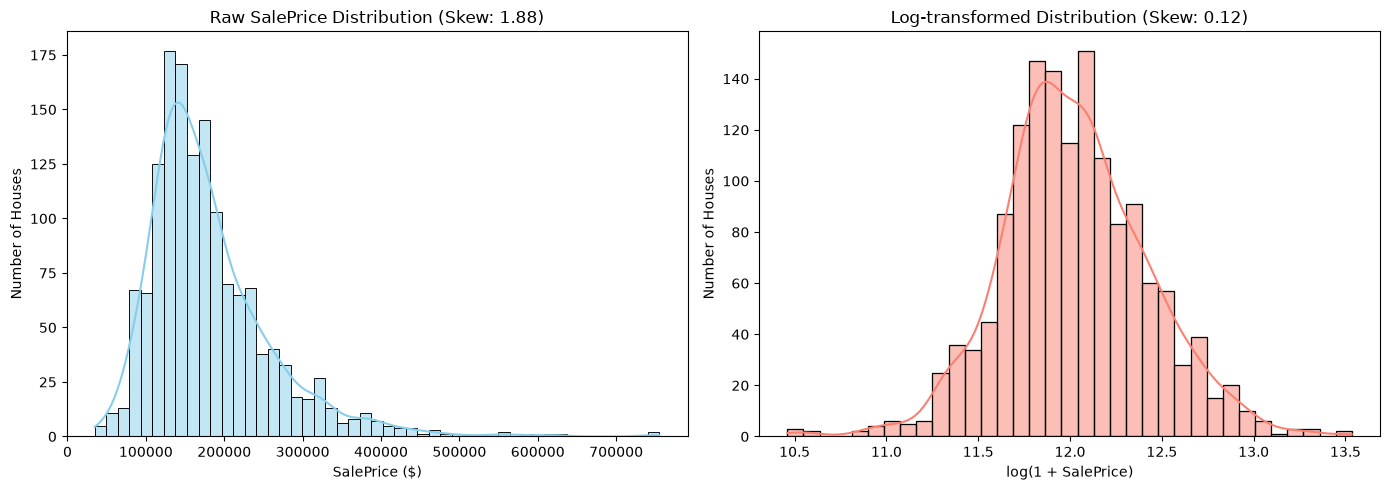

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from typing import cast


# ==========================================
# 1. SalePrice Descriptive Statistics
# ==========================================
print("--- Descriptive Statistics ---")
price_desc = df["SalePrice"].describe()
print(price_desc)
mean_price = cast(float, cast(object, price_desc["mean"]))
median_price = cast(float, cast(object, price_desc["50%"]))
print(f"Mean: {mean_price:.2f}")
print(f"Median (50%): {median_price:.2f}")
# Observation: The mean is noticeably higher than the median due to high-value outliers (luxury houses).

# ==========================================
# 2. Measuring Skewness (Raw vs Log)
# ==========================================
log_sale_price = df["SalePrice"].transform(np.log1p)
raw_skew = cast(float, df["SalePrice"].skew())
log_skew = cast(float, log_sale_price.skew())


print(f"\nRaw SalePrice Skewness: {raw_skew:.2f}")
print(f"Log-transformed SalePrice Skewness: {log_skew:.2f}")

# ==========================================
# 3. Visualization: Side-by-side Histograms
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram 1: Raw prices
sns.histplot(x=df["SalePrice"], kde=True, ax=axes[0], color="skyblue")
axes[0].set_title(f"Raw SalePrice Distribution (Skew: {raw_skew:.2f})")
axes[0].set_xlabel("SalePrice ($)")
axes[0].set_ylabel("Number of Houses")

# Histogram 2: Log-transformed prices
sns.histplot(x=log_sale_price, kde=True, ax=axes[1], color="salmon")
axes[1].set_title(f"Log-transformed Distribution (Skew: {log_skew:.2f})")
axes[1].set_xlabel("log(1 + SalePrice)")
axes[1].set_ylabel("Number of Houses")

plt.tight_layout()
plt.show()

# ==========================================
# 4. Conclusion and Decision
# ==========================================
# Conclusion: The raw price distribution is right-skewed (skewness = {raw_skew:.2f}),
# with the mean exceeding the median. Applying the logarithmic transformation
# (np.log1p) successfully reduces the skewness down to {log_skew:.2f},
# making the distribution significantly more symmetric.
#
# Decision: We will use log(SalePrice) as the target variable for training our
# regression models. This transformation aligns error optimization with relative
# (percentage) differences and should help support model homoscedasticity later
# during residual analysis.


--- 1. Top 10 Features Correlated with log(SalePrice) ---
OverallQual     0.817185
GrLivArea       0.700927
GarageCars      0.680625
GarageArea      0.650888
TotalBsmtSF     0.612134
1stFlrSF        0.596981
FullBath        0.594771
YearBuilt       0.586570
YearRemodAdd    0.565608
GarageYrBlt     0.541073
dtype: float64

--- Bottom 5 Features Correlated with log(SalePrice) ---
OverallCond     -0.036868
YrSold          -0.037263
LowQualFinSF    -0.037963
KitchenAbvGr    -0.147548
EnclosedPorch   -0.149050
dtype: float64


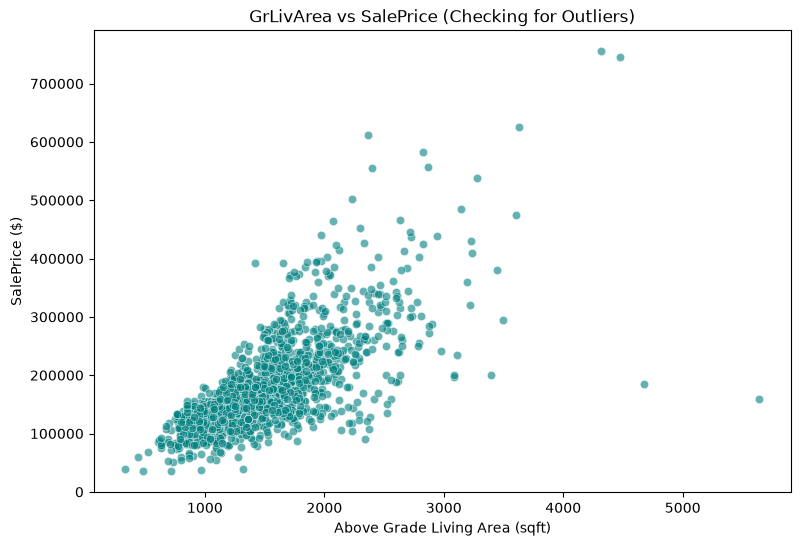


--- 2. Houses with GrLivArea > 4000 ---
      GrLivArea  SalePrice  OverallQual Neighborhood SaleCondition
523        4676     184750           10      Edwards       Partial
691        4316     755000           10      NoRidge        Normal
1182       4476     745000           10      NoRidge       Abnorml
1298       5642     160000           10      Edwards       Partial


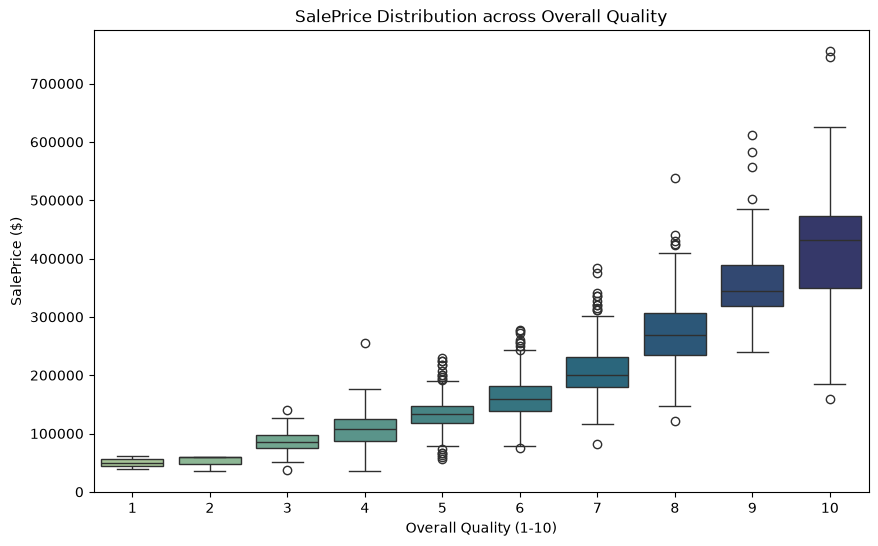


--- 4. Highly Correlated Feature Pairs (corr > 0.8) ---
GarageCars <-> GarageArea: 0.88
YearBuilt <-> GarageYrBlt: 0.83
GrLivArea <-> TotRmsAbvGrd: 0.83
TotalBsmtSF <-> 1stFlrSF: 0.82


In [39]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# ==========================================
# 1. Correlations with log_sale_price (Sorted)
# ==========================================
exclude_cols = ["Id", "SalePrice", "MSSubClass"]
num_cols = df.select_dtypes(include=[np.number]).drop(
    columns=exclude_cols, errors="ignore"
)

corrs_with_log = num_cols.corrwith(log_sale_price).sort_values(ascending=False)

print("--- 1. Top 10 Features Correlated with log(SalePrice) ---")
print(corrs_with_log.head(10))
print("\n--- Bottom 5 Features Correlated with log(SalePrice) ---")
print(corrs_with_log.tail(5))


# ==========================================
# 2. Scatter Plot: GrLivArea vs. SalePrice (Outlier Investigation)
# ==========================================
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=0.6, color="teal")
plt.title("GrLivArea vs SalePrice (Checking for Outliers)")
plt.xlabel("Above Grade Living Area (sqft)")
plt.ylabel("SalePrice ($)")
plt.show()

# Investigate all houses with GrLivArea > 4000 without pre-filtering the price
outliers = df[df["GrLivArea"] > 4000]
cols_to_show = ["GrLivArea", "SalePrice", "OverallQual", "Neighborhood", "SaleCondition"]
print("\n--- 2. Houses with GrLivArea > 4000 ---")
print(outliers[[c for c in cols_to_show if c in df.columns]])


# ==========================================
# 3. Boxplot: OverallQual vs. SalePrice
# ==========================================
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x="OverallQual",
    y="SalePrice",
    hue="OverallQual",
    palette="crest",
    legend=False
)
plt.title("SalePrice Distribution across Overall Quality")
plt.xlabel("Overall Quality (1-10)")
plt.ylabel("SalePrice ($)")
plt.show()


# ==========================================
# 4. Feature-to-Feature Correlations (Multicollinearity Check)
# ==========================================
corr_matrix = num_cols.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

high_corr_pairs = []
for col in upper_tri.columns:
    high_corrs = upper_tri.index[upper_tri[col] > 0.8].tolist()
    for row in high_corrs:
        high_corr_pairs.append((row, col, upper_tri.loc[row, col]))

print("\n--- 4. Highly Correlated Feature Pairs (corr > 0.8) ---")
sorted_pairs = sorted(high_corr_pairs, key=lambda x: x[2], reverse=True)
for f1, f2, val in sorted_pairs[:10]:
    print(f"{f1} <-> {f2}: {val:.2f}")


# ==========================================
# 5. EDA Summary & Conclusions
# ==========================================
# - Strongest Drivers: 'OverallQual' (~0.82) and 'GrLivArea' (~0.70) are the dominant
#   positive predictors for log(SalePrice).
# - Quality vs. Condition: OverallCond has a correlation close to 0, which suggests
#   that initial construction quality matters much more than current condition (acknowledging
#   that correlation only captures linear relationships and can be masked by confounding factors).
# - Negative Correlations: There are no strong negative correlations (the lowest are around -0.15).
# - Boxplot Insights: SalePrice increases monotonically with each step in OverallQuality,
#   showing distinct price jumps at higher tiers (8, 9, 10).
# - Multicollinearity: High correlations found among structural pairs (e.g., GarageCars & GarageArea).
#   Note: The YearBuilt / GarageYrBlt pair (0.83) is already addressed by our previous pipeline decision.
# - Outlier Decision & Consequences: Following Dean De Cock's recommendation, houses over 4,000 sq ft
#   will be dropped *only from the training set* inside the modeling pipeline.
#   Consequence: The model will not be reliable for mansions > 4,000 sq ft, which must be handled
#   in the web application (e.g., setting a form limit or displaying a warning banner).